# Getting started with sbi
In this tutorial, you will learn the basics of the sbi toolbox. Here is a code-snippet that you will learn to understand:

```py
from sbi.inference import NPE
from sbi.analysis import pairplot


num_simulations = 1000
theta = prior.sample((num_simulations,))
x = simulate(theta)

inference = NPE(prior)
posterior_net = inference.append_simulations(theta, x).train()
posterior = inference.build_posterior()
posterior_theta = posterior.sample((100,), x=x_o)
pairplot(posterior_theta)
```


he overall goal of simulation-based inference is to algorithmically identify parameters which are consistent with data and prior knowledge. To do so, sbi uses Bayesian inference:

$$
p(\theta|x_0) \propto p(x_0 | \theta) p(\theta)
$$

The prior 
 is a probability distribution which constraint model parameters. The likelihood 
 is implemented by a simulator. It takes parameters as input and returns simulation outputs. The sbi toolbox uses the prior and the simulator to compute the posterior , which captures parameters that are consistent with observations.

Let’s see how sbi achieves this!

## Defining the simulator and prior

As an illustrative example, we consider a simulator that takes in 3 parameters ($\theta$). For simplicity, the simulator outputs simulations of the same dimensionality and adds 1.0 and some Gaussian noise to the parameter set.



In [2]:
import torch

_ = torch.manual_seed(0)

num_dim = 3
def simulator(theta):
    # Linear Gaussian.
    return theta + 1.0 + torch.randn_like(theta) * 0.1

For the 3-dimensional parameter space we consider a uniform prior between [-2,2].

In [3]:
from sbi.utils import BoxUniform

prior = BoxUniform(low=-2 * torch.ones(num_dim), high=2 * torch.ones(num_dim))

The sbi toolbox uses neural networks to learn the relationship between parameters and data. In this example, we will use neural perform posterior estimation (NPE). To run NPE, we first instatiate a trainer, which we call inference:

In [4]:
from sbi.inference import NPE

inference = NPE(prior=prior)

The neural networks in sbi are trained on simulations, or more specifically, pairs of parameters $\theta$ which we sample from the prior and corresponding simulations `x=simulator(`$\theta$`)`. Let’s generate such a dataset:

In [5]:
num_simulations = 2000
theta = prior.sample((num_simulations,))
x = simulator(theta)
print("theta.shape", theta.shape)
print("x.shape", x.shape)

theta.shape torch.Size([2000, 3])
x.shape torch.Size([2000, 3])


We then pass the simulated data to the inference object. Both `theta` and `x` should be a `torch.Tensor` of type `float32`.

In [6]:
inference = inference.append_simulations(theta, x)

Next, we train the neural network to learn the association between the simulated data and the underlying parameters:

In [7]:
density_estimator = inference.train()

 Neural network successfully converged after 62 epochs.

Finally, we use this density estimator to build an estimator for the posterior distribution.

In [8]:
posterior = inference.build_posterior()

print(posterior)

Posterior p(θ|x) of type DirectPosterior. It samples the posterior network and rejects samples that
            lie outside of the prior bounds.


## Inferring the posterior

Let’s say we have made some observation $x_{obs}$ for which we now want to infer the posterior:

In [9]:
x_obs = torch.as_tensor([0.8, 0.6, 0.4])

The `posterior_estimator` can then be used to sample parameters $\theta$ from the posterior via `.sample()`, i.e., parameters that are likely given the observation $x$. We can also get log-probabilities under the posterior via `.log_prob()`.

For example, given the observation $x_{obs}$, we can sample from the posterior $p(\theta|x_{obs})$ as follows:

In [10]:
samples = posterior.sample((10000,), x=x_obs)

100%|██████████| 10000/10000 [00:00<00:00, 282804.65it/s]


Note that we can infer the posterior distribution for any observation $x_{obs}$ without having to run new simulations and without having to re-train. This property of sbi algorithms is called amortization.

## Visualizing the posterior

We can then visualize these posterior samples. The pairplot function visualizes all univariate marginals on the diagnonal and every combination of pairwise marginals on the upper offdiagonal:

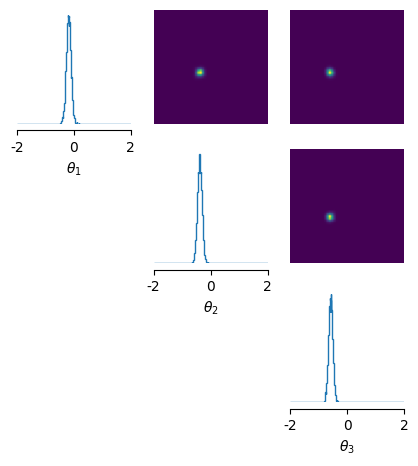

In [11]:
from sbi.analysis import pairplot

_ = pairplot(
    samples,
    limits=[[-2, 2], [-2, 2], [-2, 2]],
    figsize=(5, 5),
    labels=[r"$\theta_1$", r"$\theta_2$", r"$\theta_3$"]
)

## Assessing the predictive performance of the posterior

Congrats, you have just performed Bayesian inference with the sbi toolbox!

But, how do we know that the posterior is correct? The sbi toolbox implements a wide range of methods that diagnose potential issues (more detail here). For this tutorial, we will show only a brief heuristic check: We check whether posterior samples, when simulated, match the observed data. Such tests are called Posterior Predictive Checks (PPC). Let’s simulate posterior samples:

In [12]:
theta_posterior = posterior.sample((10000,), x=x_obs)  # Sample from posterior.
x_predictive = simulator(theta_posterior)  # Simulate data from posterior.

100%|██████████| 10000/10000 [00:00<00:00, 267377.92it/s]


And we can check whether posterior samples roughly match the observation:

In [13]:
print("Posterior predictives: ", torch.mean(x_predictive, axis=0))
print("Observation: ", x_obs)

Posterior predictives:  tensor([0.8124, 0.6143, 0.4069])
Observation:  tensor([0.8000, 0.6000, 0.4000])


Indeed, the posterior predictives are roughly centered around the observation. For any real-world application, we strongly recommend additional checks as described in this how-to guide.